# Floquet orders: predict, classify, and check

**Chapter 4 analytical notebook.** Read the [chapter](../chapters/04-periodic-floquet.md), [worked examples](../chapters/04-floquet-guide.md), and [lab](../labs/04-floquet-lab.md). The lab includes a browser explorer that runs directly on the published site.

This notebook computes allowed diffraction channels, analytical Fresnel power checks, and prescribed finite-array factors. It contains no patterned-device Maxwell solver and predicts no metasurface diffraction efficiency. All exterior indices are positive real numbers for homogeneous, isotropic, lossless media. Default lengths are in micrometers; angles are in degrees.

Restart the kernel and run all cells. Parameters are collected below. No external data, GPU, or network connection is needed during execution. For notebook sliders, install the book's `requirements-labs.txt` and set `ENABLE_WIDGETS=True`; the reference saved outputs use `False`.

## 1. Parameters and environment


In [1]:
import sys
import json
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm, ListedColormap
from IPython.display import display, HTML
from html import escape

PERIOD_UM, WAVELENGTH_UM = 3.0, 1.55
THETA_DEG, N_IN, N_OUT = 0.0, 1.0, 1.0
CUTOFF_TOL = 1e-10  # tolerance on abs(kx / (n_out*k0)) - 1
NEIGHBOR_ORDERS = 2
MAX_ENUMERATED_ORDERS = 10000
SWEEP_THETA = np.linspace(-70, 70, 281)
SWEEP_WAVELENGTH_UM = np.linspace(0.6, 3.6, 241)
ARRAY_SIZES = (8, 24, 64)
ARRAY_ANGLES_DEG = np.linspace(-89.9, 89.9, 9001)
ENABLE_WIDGETS = False

assert 0 < CUTOFF_TOL < 1e-3
assert isinstance(NEIGHBOR_ORDERS, int) and NEIGHBOR_ORDERS >= 1
assert all(isinstance(n, int) and n > 0 for n in ARRAY_SIZES)
assert np.isfinite(SWEEP_THETA).all() and np.all(np.abs(SWEEP_THETA) < 90)
assert np.isfinite(SWEEP_WAVELENGTH_UM).all() and np.all(SWEEP_WAVELENGTH_UM > 0)
print(f"Python {sys.version.split()[0]}; NumPy {np.__version__}; Matplotlib {matplotlib.__version__}")
print("Convention: exp(-i omega t), exp(i k.r), incidence from z<0; lengths in micrometers.")
print("Evidence: analytical channels, Fresnel interfaces, and prescribed scalar array factors.")

def show_table(headers, rows):
    header = "".join(f'<th scope="col">{escape(str(x))}</th>' for x in headers)
    body = "".join("<tr>" + "".join(f"<td>{escape(str(x))}</td>" for x in row) + "</tr>" for row in rows)
    display(HTML('<div style="overflow-x:auto;max-width:100%"><table><thead><tr>'+
                 header+'</tr></thead><tbody>'+body+'</tbody></table></div>'))


Python 3.12.1; NumPy 2.4.6; Matplotlib 3.11.1
Convention: exp(-i omega t), exp(i k.r), incidence from z<0; lengths in micrometers.
Evidence: analytical channels, Fresnel interfaces, and prescribed scalar array factors.


## 2. Define the channel calculation

The dimensionless tangential coordinate is

$$q_m=n_i\sin\theta_i+m\lambda_0/\Lambda.$$

Compare $|q_m/n_o|$ with one. The positive outgoing-distance root is $\kappa/k_0=\sqrt{n_o^2-q_m^2}$, with a positive imaginary part for closed channels. Reflected waves use the opposite laboratory $k_z$ sign because their outward direction points toward negative $z$.

The open-order bounds come from solving $-n_o<q_m<n_o$ for the integer $m$. We use a conservative enclosing interval plus closed neighbors. This avoids silently dropping orders when the period or index grows. The explicit enumeration guard raises an error for an unreasonable array size rather than exhausting memory.

Near cutoff, the state is a tolerance-based classification. Its reported $\pm90^\circ$ is the limiting grazing angle, not a finite-normal-power beam. Evanescent orders receive no real angle.


In [2]:
def validate_inputs(period_um, wavelength_um, theta_deg, n_in, n_out):
    values = np.array([period_um, wavelength_um, theta_deg, n_in, n_out], dtype=float)
    if not np.isfinite(values).all():
        raise ValueError("All physical parameters must be finite")
    if min(period_um, wavelength_um, n_in, n_out) <= 0:
        raise ValueError("Use positive period, wavelength, and real indices")
    if abs(theta_deg) >= 90:
        raise ValueError("Use an incidence angle strictly between -90 and 90 degrees")

def classify_q(q, n_out, tol=CUTOFF_TOL):
    distance = np.abs(np.asarray(q, dtype=float)/n_out)-1
    return np.where(distance < -tol, "open", np.where(distance > tol, "closed", "grazing"))

def floquet_orders(period_um, wavelength_um, theta_deg, n_in, n_out,
                   neighbors=NEIGHBOR_ORDERS, tol=CUTOFF_TOL):
    validate_inputs(period_um, wavelength_um, theta_deg, n_in, n_out)
    if not isinstance(neighbors, int) or neighbors < 1 or not 0 < tol < 1e-3:
        raise ValueError("Use at least one closed neighbor and a small positive cutoff tolerance")
    q_incident = n_in*np.sin(np.deg2rad(theta_deg))
    step = wavelength_um/period_um
    lower, upper = (-n_out-q_incident)/step, (n_out-q_incident)/step
    # Slightly expand by the classification tolerance so all near-grazing cases are included.
    padding = tol*n_out/step
    first = int(np.floor(lower-padding))-neighbors
    last = int(np.ceil(upper+padding))+neighbors
    if last-first+1 > MAX_ENUMERATED_ORDERS:
        raise ValueError("Too many orders for this teaching notebook; revise the parameter range")
    m = np.arange(first, last+1, dtype=int)
    q = q_incident + m*step
    state = classify_q(q, n_out, tol)
    kz_out_over_k0 = np.sqrt((n_out*n_out-q*q).astype(complex))
    angle = np.full(q.shape, np.nan)
    is_open, is_grazing = state == "open", state == "grazing"
    angle[is_open] = np.rad2deg(np.arcsin(q[is_open]/n_out))
    angle[is_grazing] = np.sign(q[is_grazing])*90
    assert np.all(kz_out_over_k0.real >= 0) and np.all(kz_out_over_k0.imag >= 0)
    return dict(m=m, q=q, state=state, angle_deg=angle,
                kz_out_over_k0=kz_out_over_k0, q_incident=q_incident)

def open_ids(result):
    return result["m"][result["state"] == "open"].tolist()

def print_channels(result, label):
    print(label, "open orders:", open_ids(result))
    show_table(["m", "kx/k0", "State", "Angle (degrees)", "Outward kz/k0"],
               [(int(m), f"{q:.6f}", state, "undefined" if np.isnan(angle) else f"{angle:.4f}", f"{kz:.5g}")
                for m, q, state, angle, kz in zip(result["m"], result["q"], result["state"],
                                                result["angle_deg"], result["kz_out_over_k0"])])

transmitted = floquet_orders(PERIOD_UM, WAVELENGTH_UM, THETA_DEG, N_IN, N_OUT)
reflected = floquet_orders(PERIOD_UM, WAVELENGTH_UM, THETA_DEG, N_IN, N_IN)
print_channels(transmitted, "Transmission region")
print("Reflection region open orders:", open_ids(reflected))
print("All table angles are channel directions; no amplitude or efficiency has been assigned.")


Transmission region open orders: [-1, 0, 1]


m,kx/k0,State,Angle (degrees),Outward kz/k0
-4,-2.066667,closed,undefined,0+1.8086j
-3,-1.550000,closed,undefined,0+1.1843j
-2,-1.033333,closed,undefined,0+0.26034j
-1,-0.516667,open,-31.1089,0.85619+0j
0,0.000000,open,0.0000,1+0j
1,0.516667,open,31.1089,0.85619+0j
2,1.033333,closed,undefined,0+0.26034j
3,1.550000,closed,undefined,0+1.1843j
4,2.066667,closed,undefined,0+1.8086j


Reflection region open orders: [-1, 0, 1]
All table angles are channel directions; no amplitude or efficiency has been assigned.


## 3. Check independent analytical cases

The checks below cover known order sets and angles, exact cutoff and both sides of it, the decaying outgoing branch, Bloch-phase equivalence, input validation, and agreement with a much wider brute-force integer window. The latter checks enumeration, not the correctness of the physical formula by itself.

The microwave case uses $\lambda_0=30$ mm and $\Lambda=25$ mm, corresponding to the rounded classroom convention $c=3.00\times10^8$ m/s at 10 GHz. Converting both lengths to micrometers leaves their ratio unchanged.


In [3]:
reference = floquet_orders(3, 1.55, 0, 1, 1)
glass = floquet_orders(3, 1.55, 0, 1, 1.5)
primitive = floquet_orders(0.5, 1.55, 0, 1, 1)
assert open_ids(reference) == [-1, 0, 1]
assert open_ids(glass) == [-2, -1, 0, 1, 2]
assert open_ids(primitive) == [0]
assert np.isclose(reference["angle_deg"][reference["m"] == 1][0], 31.10892251052852)
assert np.isnan(reference["angle_deg"][reference["state"] == "closed"]).all()

cutoff_normal = floquet_orders(1.55, 1.55, 0, 1, 1)
assert cutoff_normal["m"][cutoff_normal["state"] == "grazing"].tolist() == [-1, 1]
assert open_ids(cutoff_normal) == [0]
cutoff_deg = float(np.rad2deg(np.arcsin(1.55/0.8-1.5)))
states = []
for offset in (-0.01, 0, 0.01):
    result = floquet_orders(0.8, 1.55, cutoff_deg+offset, 1, 1.5)
    states.append(result["state"][result["m"] == -1][0])
assert states == ["closed", "grazing", "open"]

microwave = floquet_orders(25000, 30000, 20, 1, 1)
assert open_ids(microwave) == [-1, 0]
microwave_angle = float(microwave["angle_deg"][microwave["m"] == -1][0])
assert np.isclose(microwave_angle, -59.09051239302117)
phase_advance = 2*np.pi*(25000/30000)*np.sin(np.deg2rad(20))
multiplier = np.exp(1j*phase_advance)
for m in microwave["m"]:
    assert np.allclose(np.exp(1j*(phase_advance+2*np.pi*m)), multiplier)

closed_index = int(np.flatnonzero(reference["m"] == 2)[0])
alpha_per_um = (2*np.pi/1.55)*reference["kz_out_over_k0"][closed_index].imag
assert alpha_per_um > 0
assert abs(np.exp(-alpha_per_um*2)) < abs(np.exp(-alpha_per_um)) < 1
# Reflected kz=-i*alpha: at z=-s, exp(i*kz*z)=exp(-alpha*s), also decaying.
assert np.isclose(abs(np.exp(1j*(-1j*alpha_per_um)*(-1))), np.exp(-alpha_per_um))

wide_m = np.arange(-200, 201)
for period, wavelength, theta, ni, no in [(3, 1.55, 0, 1, 1), (20, .5, 57, 1.2, 2),
                                         (.8, 1.55, -45, 1, 1.5), (1, 2, 65, 2, 1)]:
    result = floquet_orders(period, wavelength, theta, ni, no)
    q = ni*np.sin(np.deg2rad(theta)) + wide_m*wavelength/period
    expected = wide_m[classify_q(q, no) == "open"].tolist()
    assert open_ids(result) == expected

for invalid in [(0, 1, 0, 1, 1), (1, 1, 90, 1, 1), (1, 1, 0, -1, 1), (1, np.nan, 0, 1, 1)]:
    try:
        floquet_orders(*invalid)
    except ValueError:
        pass
    else:
        raise AssertionError("Invalid physical input was accepted")

validation_report = dict(air_open=open_ids(reference), glass_open=open_ids(glass),
                         primitive_open=open_ids(primitive), microwave_open=open_ids(microwave),
                         first_air_angle_deg=float(reference["angle_deg"][reference["m"] == 1][0]),
                         microwave_negative_angle_deg=microwave_angle,
                         microwave_phase_deg=float(np.rad2deg(phase_advance)),
                         cutoff_glass_deg=cutoff_deg, cutoff_sequence=states,
                         closed_m2_amplitude_decay_length_um=float(1/alpha_per_um))
print("Analytical channel, phase, branch, enumeration, and invalid-input checks passed.")
print(json.dumps(validation_report, indent=2))


Analytical channel, phase, branch, enumeration, and invalid-input checks passed.
{
  "air_open": [
    -1,
    0,
    1
  ],
  "glass_open": [
    -2,
    -1,
    0,
    1,
    2
  ],
  "primitive_open": [
    0
  ],
  "microwave_open": [
    -1,
    0
  ],
  "first_air_angle_deg": 31.10892251052852,
  "microwave_negative_angle_deg": -59.09051239302117,
  "microwave_phase_deg": 102.60604299770061,
  "cutoff_glass_deg": 25.94447977237001,
  "cutoff_sequence": [
    "closed",
    "grazing",
    "open"
  ],
  "closed_m2_amplitude_decay_length_um": 0.9475631587813499
}


## 4. See the repeat before choosing a Bloch phase

**Predict:** if six ridge widths differ, which translation reproduces the whole structure? If all widths become equal, which additional symmetry appears?

The top row sketches two illustrative geometries at pitch $p=0.5\,\mu\mathrm m$. Their displayed six-slot box has length $\Lambda=3\,\mu\mathrm m$. Ridge height and material properties are deliberately unspecified: these drawings explain translation symmetry and are not a fabricated device simulation. The six distinct widths require the full sequence to repeat; identical ridges repeat after $p$.

The lower-left phasors track the incident field at equivalent points separated by $\Lambda$, for $\lambda_0=1.55\,\mu\mathrm m$, $n_i=1$, and $\theta_i=12^\circ$. Equal geometry does not imply equal complex field: the field rotates by $k_{x,i}\Lambda$ per repeat. Every Floquet harmonic has this same multiplier.

For six identical primitive cells, removing the incident Bloch factor leaves a $p$-periodic function. Its supercell Fourier coefficient contains the normalized root sum

$$S_m=\frac{1}{6}\sum_{j=0}^{5}e^{-2\pi i m j/6}.$$

This sum is one for $m=6\ell$ and zero otherwise. The lower-right panel shows the six vectors for $m=1$: their head-to-tail polygon closes. A channel can be geometrically open while its amplitude is forced to zero by symmetry. The [coupling investigation](../labs/10-coupling-lab.md) checks this rule using an executed Maxwell model with a different ridge geometry.


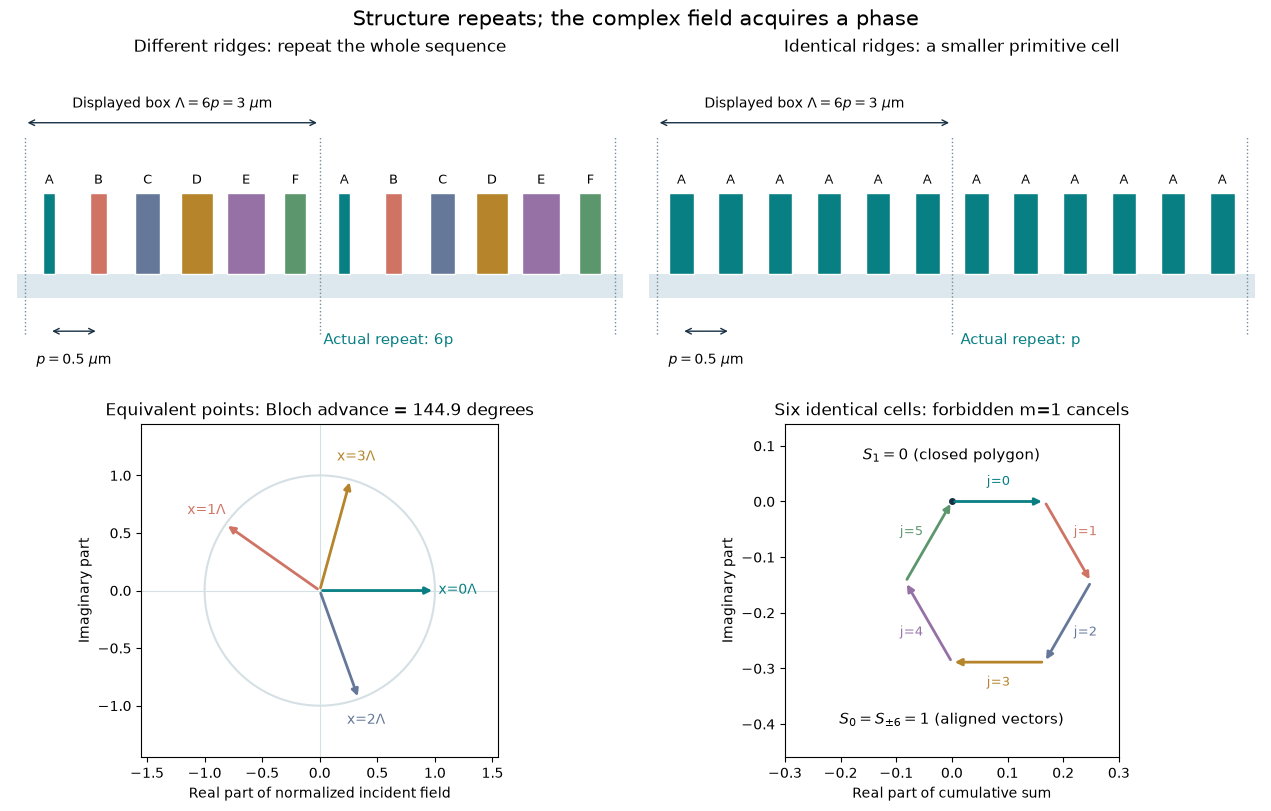

Root-sum selection rule checked for 37 orders; phase advance 144.8675 degrees.


In [4]:
from matplotlib.patches import Rectangle, FancyArrowPatch

SCHEMATIC_PITCH_UM = 0.5
SCHEMATIC_PERIOD_UM = 6*SCHEMATIC_PITCH_UM
SCHEMATIC_WIDTHS_UM = np.array([.12, .18, .25, .32, .39, .22])
BLOCH_DEMO_THETA_DEG, BLOCH_DEMO_WAVELENGTH_UM = 12.0, 1.55
phase_step = (2*np.pi/BLOCH_DEMO_WAVELENGTH_UM)*np.sin(np.deg2rad(BLOCH_DEMO_THETA_DEG))*SCHEMATIC_PERIOD_UM
orders_symmetry = np.arange(-18, 19)
root_sums = np.mean(np.exp(-2j*np.pi*orders_symmetry[:, None]*np.arange(6)/6), axis=1)
assert np.allclose(root_sums, orders_symmetry % 6 == 0, atol=1e-14)
assert np.allclose(np.exp(1j*(phase_step+2*np.pi*orders_symmetry)), np.exp(1j*phase_step), atol=1e-13)

fig, axes = plt.subplots(2, 2, figsize=(12.6, 8), constrained_layout=True)
colors = ['#087f83', '#cf7465', '#65789a', '#b5842b', '#9571a6', '#5b966d']
for ax, identical in zip(axes[0], (False, True)):
    widths = np.repeat(.25, 6) if identical else SCHEMATIC_WIDTHS_UM
    ax.add_patch(Rectangle((-.08, -.13), 6.16, .13, facecolor='#dce8ed', edgecolor='none'))
    for j in range(12):
        center = (j+.5)*SCHEMATIC_PITCH_UM
        width = widths[j % 6]
        ax.add_patch(Rectangle((center-width/2, 0), width, .44,
                               facecolor=colors[0] if identical else colors[j % 6], edgecolor='white'))
        ax.text(center, .49, 'A' if identical else 'ABCDEF'[j % 6], ha='center', fontsize=9)
    for boundary in (0, 3, 6):
        ax.axvline(boundary, ymin=.18, ymax=.77, color='#788a99', ls=':', lw=1)
    ax.annotate('', xy=(0, .82), xytext=(3, .82), arrowprops=dict(arrowstyle='<->', color='#173044'))
    ax.text(1.5, .9, r'Displayed box $\Lambda=6p=3\ \mu$m', ha='center', fontsize=10)
    ax.annotate('', xy=(.25, -.31), xytext=(.75, -.31), arrowprops=dict(arrowstyle='<->', color='#173044'))
    ax.text(.5, -.49, r'$p=0.5\ \mu$m', ha='center', fontsize=10)
    ax.text(3.7, -.38, 'Actual repeat: p' if identical else 'Actual repeat: 6p', ha='center', fontsize=11, color='#087f83')
    ax.set(xlim=(-.15, 6.15), ylim=(-.65, 1.16), title='Identical ridges: a smaller primitive cell' if identical else 'Different ridges: repeat the whole sequence')
    ax.set_axis_off()

ax = axes[1, 0]
circle = np.exp(1j*np.linspace(0, 2*np.pi, 301))
ax.plot(circle.real, circle.imag, color='#d5e0e5')
for j, color in enumerate(colors[:4]):
    value = np.exp(1j*j*phase_step)
    ax.annotate('', xy=(value.real, value.imag), xytext=(0, 0), arrowprops=dict(arrowstyle='-|>', lw=2, color=color))
    ax.text(1.2*value.real, 1.2*value.imag, f'x={j}' + r'$\Lambda$', ha='center', va='center', color=color)
ax.axhline(0, color='#d5e0e5', lw=.8); ax.axvline(0, color='#d5e0e5', lw=.8)
ax.set(xlim=(-1.55, 1.55), ylim=(-1.45, 1.45), xlabel='Real part of normalized incident field', ylabel='Imaginary part',
       title=f'Equivalent points: Bloch advance = {np.rad2deg(phase_step):.1f} degrees')
ax.set_aspect('equal')

ax = axes[1, 1]
vectors = np.exp(-2j*np.pi*np.arange(6)/6)/6
corners = np.r_[0j, np.cumsum(vectors)]
for j, color in enumerate(colors):
    a, b = corners[j:j+2]
    ax.annotate('', xy=(b.real, b.imag), xytext=(a.real, a.imag), arrowprops=dict(arrowstyle='-|>', lw=2, color=color))
    midpoint = (a+b)/2
    center = np.mean(corners[:-1])
    label = midpoint + .25*(midpoint-center)
    ax.text(label.real, label.imag, f'j={j}', ha='center', va='center', fontsize=9, color=color)
ax.plot(0, 0, 'o', color='#173044', ms=4)
ax.text(0, .075, r'$S_1=0$ (closed polygon)', ha='center', fontsize=11)
ax.text(0, -.4, r'$S_0=S_{\pm6}=1$ (aligned vectors)', ha='center', fontsize=11)
ax.set(xlim=(-.3, .3), ylim=(-.46, .14), xlabel='Real part of cumulative sum', ylabel='Imaginary part',
       title='Six identical cells: forbidden m=1 cancels')
ax.set_aspect('equal')
fig.suptitle('Structure repeats; the complex field acquires a phase', fontsize=15)
plt.show()
print(f'Root-sum selection rule checked for {len(orders_symmetry)} orders; phase advance {np.rad2deg(phase_step):.4f} degrees.')


## 5. Map channels across incidence and wavelength

The left plot compares output light cones at one reference condition. The right plot counts open transmitted orders across the editable sweep. Grazing channels are not counted as ordinary open channels. The integer range is chosen from the entire sweep's bounds, not only its initial wavelength or angle.

The constant indices here are teaching assumptions. For a dispersive material, evaluate its actual index at every wavelength. A channel-count color map is not an efficiency spectrum.


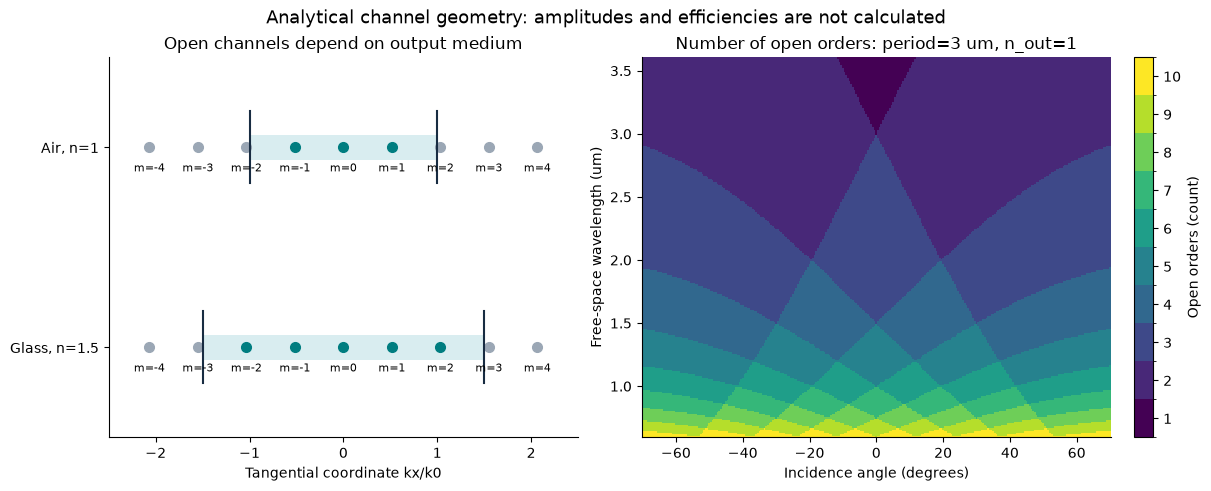

In [5]:
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), constrained_layout=True)
ax = axes[0]
for row, (name, no) in enumerate([("Air output", 1.0), ("Glass output", 1.5)]):
    case = floquet_orders(PERIOD_UM, WAVELENGTH_UM, THETA_DEG, N_IN, no)
    ax.plot([-no, no], [row, row], color="#d9edf0", lw=18, solid_capstyle="butt")
    for m, q, state in zip(case["m"], case["q"], case["state"]):
        if abs(q) > 2.5:
            continue
        color = {"open": "#007d80", "grazing": "#b76a00", "closed": "#9ba7b5"}[state]
        ax.plot(q, row, "o", color=color, ms=7)
        ax.text(q, row+0.12, f"m={m}", ha="center", fontsize=8)
    ax.plot([-no, -no], [row-.18, row+.18], color="#182c42")
    ax.plot([no, no], [row-.18, row+.18], color="#182c42")
ax.set(xlabel="Tangential coordinate kx/k0", yticks=[0, 1], yticklabels=["Air, n=1", "Glass, n=1.5"],
       xlim=(-2.5, 2.5), ylim=(-.45, 1.45), title="Open channels depend on output medium")
ax.invert_yaxis()

q_inc = N_IN*np.sin(np.deg2rad(SWEEP_THETA))
step_min = np.min(SWEEP_WAVELENGTH_UM)/PERIOD_UM
max_order = int(np.ceil((N_OUT+np.max(np.abs(q_inc)))/step_min))+NEIGHBOR_ORDERS
if 2*max_order+1 > MAX_ENUMERATED_ORDERS:
    raise ValueError("Sweep requires too many diffraction orders")
count_map = np.zeros((len(SWEEP_WAVELENGTH_UM), len(SWEEP_THETA)), dtype=int)
for m in range(-max_order, max_order+1):
    q = q_inc[None, :] + m*SWEEP_WAVELENGTH_UM[:, None]/PERIOD_UM
    count_map += classify_q(q, N_OUT) == "open"
assert np.isfinite(count_map).all()
levels = np.arange(count_map.min()-.5, count_map.max()+1.5)
cmap = plt.get_cmap("viridis", len(levels)-1)
im = axes[1].pcolormesh(SWEEP_THETA, SWEEP_WAVELENGTH_UM, count_map, shading="auto",
                        cmap=cmap, norm=BoundaryNorm(levels, cmap.N))
axes[1].set(xlabel="Incidence angle (degrees)", ylabel="Free-space wavelength (um)",
            title=f"Number of open orders: period={PERIOD_UM:g} um, n_out={N_OUT:g}")
fig.colorbar(im, ax=axes[1], label="Open orders (count)", ticks=np.arange(count_map.min(), count_map.max()+1))
fig.suptitle("Analytical channel geometry: amplitudes and efficiencies are not calculated", fontsize=13)
plt.show()


## 6. Watch an outgoing harmonic change character

These are **individual analytical TE harmonics in a homogeneous output medium**, not near fields from a solved grating. Each has $E_y(x,0)=e^{ik_xx}$ and unit surface amplitude. Write $q=k_x/k_0$, $s\geq0$ for distance outward from the interface, and $\bar\kappa=\sqrt{n_o^2-q^2}$. Then

$$E_y(x,s)=e^{ik_0 q x}e^{ik_0\bar\kappa s}.$$

For nonmagnetic media, Maxwell's equation gives $Z_0H_x=-\bar\kappa E_y$ on the transmitted side. The normalized outward time-average flux is

$$2Z_0 S_s=\operatorname{Re}(\bar\kappa)|E_y|^2.$$

For the reflected side, the laboratory normal wavenumber and the outward normal both reverse. The outward flux uses the same positive-distance expression. At grazing, a bounded field carries zero normal flux even though its real field oscillates along $x$. When $\bar\kappa=i\alpha/k_0$, the amplitude decays as $e^{-\alpha s}$, the squared amplitude as $e^{-2\alpha s}$, and the isolated harmonic has zero normal time-average flux. A zero normal flux does not mean a zero field or no tangential energy flow.

**Predict:** which panel changes if you move farther from the surface? Which field has a finite amplitude decay length? The checks below calculate flux directly from the complex vector cross product and compare it with the stated expression.


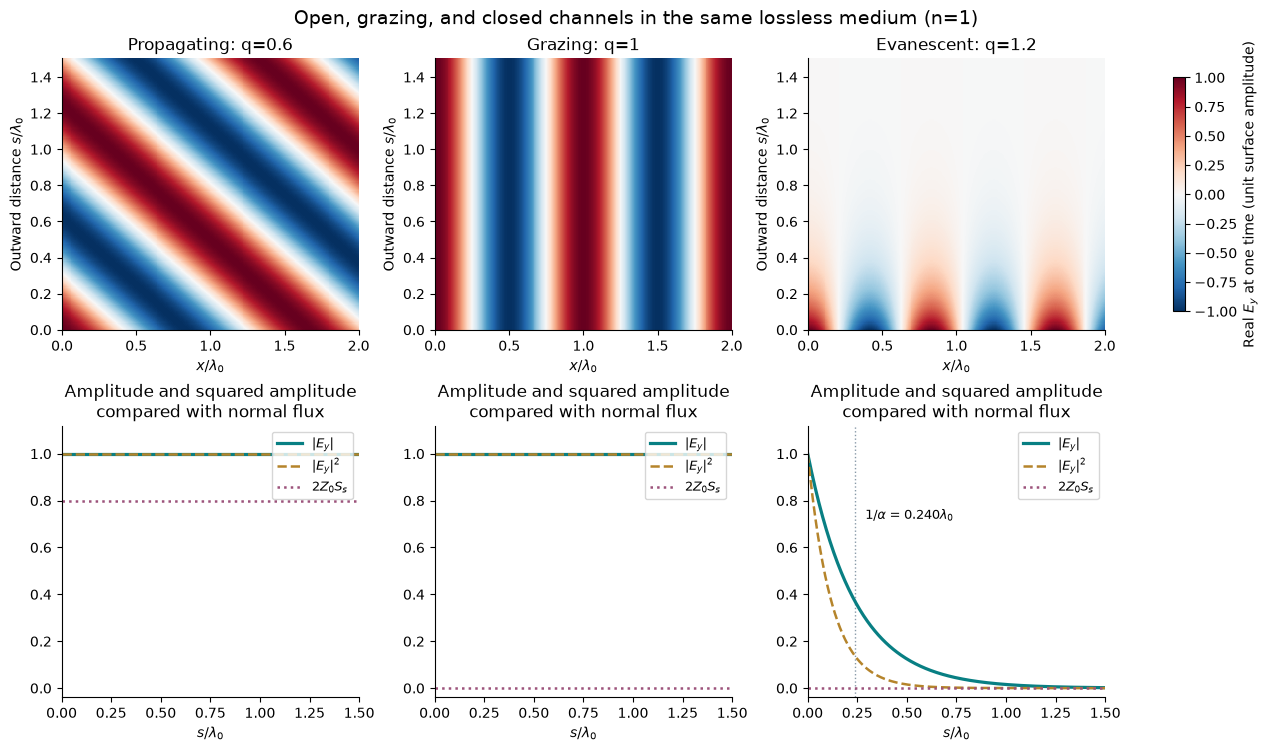

Harmonic,Outgoing kappa/k0,Normalized normal flux at s=0
Propagating,0.8+0j,0.8
Grazing,0+0j,0
Evanescent,0+0.66332j,0


Envelope, amplitude/intensity decay lengths, and independent vector Poynting-flux checks passed.


In [6]:
OUTGOING_Q = np.array([.6, 1.0, 1.2])
OUTGOING_INDEX = 1.0
x_lambda = np.linspace(0, 2, 301)
s_lambda = np.linspace(0, 1.5, 241)
X, S = np.meshgrid(x_lambda, s_lambda)
fig, axes = plt.subplots(2, 3, figsize=(12.6, 7.4), constrained_layout=True)
flux_checks = []
for col, (q, name) in enumerate(zip(OUTGOING_Q, ('Propagating', 'Grazing', 'Evanescent'))):
    kappa_bar = np.sqrt(complex(OUTGOING_INDEX**2-q*q))
    field = np.exp(2j*np.pi*(q*X+kappa_bar*S))
    image = axes[0, col].pcolormesh(X, S, field.real, cmap='RdBu_r', vmin=-1, vmax=1, shading='auto', rasterized=True)
    axes[0, col].set(xlabel=r'$x/\lambda_0$', ylabel=r'Outward distance $s/\lambda_0$',
                     title=f'{name}: q={q:g}')
    envelope = np.exp(-2*np.pi*kappa_bar.imag*s_lambda)
    E = np.zeros((len(s_lambda), 3), dtype=complex)
    H_scaled = np.zeros_like(E)
    E[:, 1] = np.exp(2j*np.pi*kappa_bar*s_lambda)
    H_scaled[:, 0] = -kappa_bar*E[:, 1]
    H_scaled[:, 2] = q*E[:, 1]
    vector_flux = np.cross(E, H_scaled.conj()).real[:, 2]
    expected_flux = kappa_bar.real*envelope**2
    assert np.allclose(vector_flux, expected_flux, atol=1e-13)
    assert np.allclose(np.abs(field[:, 0]), envelope, atol=1e-13)
    if kappa_bar.imag > 0:
        decay_lambda = 1/(2*np.pi*kappa_bar.imag)
        assert np.isclose(abs(np.exp(2j*np.pi*kappa_bar*decay_lambda)), np.exp(-1))
        assert np.isclose(abs(np.exp(2j*np.pi*kappa_bar*(decay_lambda/2)))**2, np.exp(-1))
        assert np.all(vector_flux == 0)
        axes[1, col].axvline(decay_lambda, color='#8899a8', ls=':', lw=1)
        axes[1, col].text(decay_lambda+.05, .72, r'$1/\alpha$' + f' = {decay_lambda:.3f}' + r'$\lambda_0$', fontsize=9)
    axes[1, col].plot(s_lambda, envelope, color='#087f83', lw=2.3, label=r'$|E_y|$')
    axes[1, col].plot(s_lambda, envelope**2, color='#b5842b', lw=1.8, ls='--', label=r'$|E_y|^2$')
    axes[1, col].plot(s_lambda, vector_flux, color='#9c527b', lw=1.8, ls=':', label=r'$2Z_0 S_s$')
    axes[1, col].set(xlabel=r'$s/\lambda_0$', ylim=(-.04, 1.12), xlim=(0, 1.5),
                     title='Amplitude and squared amplitude\ncompared with normal flux')
    axes[1, col].legend(fontsize=9, loc='upper right')
    flux_checks.append((name, f'{kappa_bar:.5g}', f'{vector_flux[0]:.5g}'))
fig.colorbar(image, ax=list(axes[0]), label=r'Real $E_y$ at one time (unit surface amplitude)', shrink=.86)
fig.suptitle('Open, grazing, and closed channels in the same lossless medium (n=1)', fontsize=14)
plt.show()
show_table(['Harmonic', 'Outgoing kappa/k0', 'Normalized normal flux at s=0'], flux_checks)
print('Envelope, amplitude/intensity decay lengths, and independent vector Poynting-flux checks passed.')


## 7. Check power with a flat interface

For a nonmagnetic TE flat interface, let $\zeta_i=n_i\cos\theta_i$ and $\zeta_t=\sqrt{n_t^2-(n_i\sin\theta_i)^2}$ on the outgoing branch. Then

$$r=\frac{\zeta_i-\zeta_t}{\zeta_i+\zeta_t},\quad t=\frac{2\zeta_i}{\zeta_i+\zeta_t},\quad R=|r|^2,\quad T=\frac{\operatorname{Re}\zeta_t}{\zeta_i}|t|^2.$$

The normalization factor is essential. In total internal reflection, $\zeta_t$ is imaginary, so the outgoing evanescent field has zero normal transmitted power and $R=1$. This analytical benchmark is independent of a future patterned-grating simulation. An artificial periodic box cannot make a flat interface excite non-specular orders.


In [7]:
def fresnel_te(n_in, n_out, theta_deg):
    validate_inputs(1, 1, theta_deg, n_in, n_out)
    zi = n_in*np.cos(np.deg2rad(theta_deg))
    q = n_in*np.sin(np.deg2rad(theta_deg))
    zt = np.sqrt(complex(n_out*n_out-q*q))
    r, t = (zi-zt)/(zi+zt), 2*zi/(zi+zt)
    return r, t, float(abs(r)**2), float(zt.real/zi*abs(t)**2)

normal = fresnel_te(1, 1.5, 0)
tir = fresnel_te(1.5, 1, 60)
assert np.allclose(normal, [-.2, .8, .04, .96])
assert np.isclose(tir[2], 1) and np.isclose(tir[3], 0)
max_power_residual = 0.0
for ni, no in [(1, 1.5), (1.5, 1), (1, 1)]:
    for theta in np.linspace(-80, 80, 161):
        _, _, R, T = fresnel_te(ni, no, theta)
        max_power_residual = max(max_power_residual, abs(R+T-1))
assert max_power_residual < 1e-12
show_table(["Interface case", "r (field)", "t (field)", "R (power)", "T (power)"],
           [(name, f"{r:.6g}", f"{t:.6g}", f"{R:.6g}", f"{T:.6g}")
            for name, (r, t, R, T) in [("Normal: 1 to 1.5", normal), ("TIR: 1.5 to 1, 60 deg", tir)]])
print(f"Maximum Fresnel power residual over 483 analytical checks: {max_power_residual:.3e}")


Interface case,r (field),t (field),R (power),T (power)
Normal: 1 to 1.5,-0.2+0j,0.8+0j,0.04,0.96
"TIR: 1.5 to 1, 60 deg",-0.1-0.994987j,0.9-0.994987j,1,0


Maximum Fresnel power residual over 483 analytical checks: 4.441e-16


## 8. Finite arrays have finite angular widths

Use the directly evaluated scalar factor

$$\mathcal A_N(\theta)=N^{-1}\sum_{j=0}^{N-1}\exp[ij\Lambda(k_{x,i}-n_o k_0\sin\theta)].$$

All source weights are prescribed and equal after accounting for incident phase. There is no element pattern, coupling calculation, or electromagnetic boundary solution. The vertical markers below are open Floquet directions from the same physical parameters. A normalized squared scalar sum is not a power-normalized diffraction efficiency.


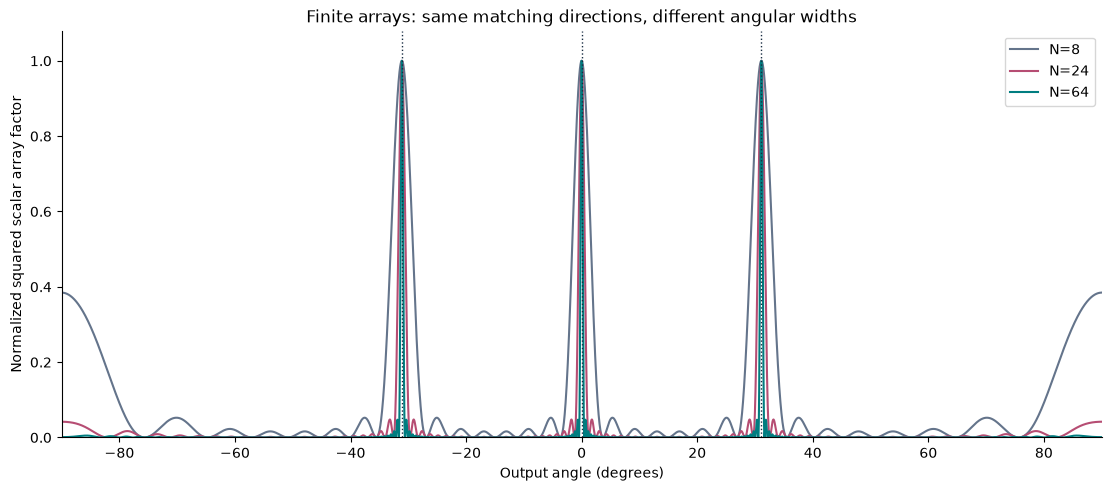

Array-factor values equal one at every open Floquet direction, within floating-point tolerance.


In [8]:
def array_factor(theta_deg, n_elements, period_um, wavelength_um, theta_incident, n_in, n_out):
    validate_inputs(period_um, wavelength_um, theta_incident, n_in, n_out)
    phase = (2*np.pi*period_um/wavelength_um)*(
        n_in*np.sin(np.deg2rad(theta_incident))-n_out*np.sin(np.deg2rad(np.asarray(theta_deg))))
    return np.mean(np.exp(1j*np.arange(n_elements)[:, None]*np.atleast_1d(phase)[None, :]), axis=0)

fig, ax = plt.subplots(figsize=(11, 4.8), constrained_layout=True)
for size, color in zip(ARRAY_SIZES, ("#64748b", "#b64d73", "#007d80")):
    factor = array_factor(ARRAY_ANGLES_DEG, size, PERIOD_UM, WAVELENGTH_UM, THETA_DEG, N_IN, N_OUT)
    assert np.max(np.abs(factor)) <= 1+1e-12
    ax.plot(ARRAY_ANGLES_DEG, np.abs(factor)**2, color=color, label=f"N={size}")
for angle in transmitted["angle_deg"][transmitted["state"] == "open"]:
    ax.axvline(angle, color="#182c42", ls=":", lw=1)
    for size in ARRAY_SIZES:
        at_order = array_factor([angle], size, PERIOD_UM, WAVELENGTH_UM, THETA_DEG, N_IN, N_OUT)
        assert np.allclose(np.abs(at_order), 1, atol=1e-12)
ax.set(xlabel="Output angle (degrees)", ylabel="Normalized squared scalar array factor",
       title="Finite arrays: same matching directions, different angular widths", xlim=(-90, 90), ylim=(0, 1.08))
ax.legend()
plt.show()
print("Array-factor values equal one at every open Floquet direction, within floating-point tolerance.")


### Verify the geometric-series form and first nulls

With $\psi=\Lambda(k_{x,i}-n_ok_0\sin\theta)$, the finite sum equals

$$\mathcal A_N=e^{i(N-1)\psi/2}\frac{\sin(N\psi/2)}{N\sin(\psi/2)}.$$

At $\psi=2\pi\ell$, use the continuous value one. Near a maximum at $\theta_m$, the first nulls satisfy $\sin\theta-\sin\theta_m=\pm\lambda_0/(Nn_o\Lambda)$, provided those sine values are inside $[-1,1]$. The approximate one-sided angular width is $\lambda_0/(Nn_o\Lambda\cos\theta_m)$ radians away from grazing. The exact sine-coordinate expression is preferable near the horizon.


In [9]:
def array_factor_closed_form(phase, n_elements):
    # Wrapping removes removable singularities at every 2*pi multiple.
    wrapped = (np.asarray(phase)+np.pi) % (2*np.pi)-np.pi
    ratio = np.sinc(n_elements*wrapped/(2*np.pi))/np.sinc(wrapped/(2*np.pi))
    return np.exp(.5j*(n_elements-1)*wrapped)*ratio

array_formula_error, first_null_error = 0.0, 0.0
for size in ARRAY_SIZES:
    phase = 2*np.pi*PERIOD_UM/WAVELENGTH_UM*(N_IN*np.sin(np.deg2rad(THETA_DEG))-N_OUT*np.sin(np.deg2rad(ARRAY_ANGLES_DEG)))
    direct = array_factor(ARRAY_ANGLES_DEG, size, PERIOD_UM, WAVELENGTH_UM, THETA_DEG, N_IN, N_OUT)
    array_formula_error = max(array_formula_error, float(np.max(np.abs(direct-array_factor_closed_form(phase, size)))))
    assert np.allclose(array_factor_closed_form(2*np.pi*np.arange(-3, 4), size), 1)
    for angle in transmitted['angle_deg'][transmitted['state'] == 'open']:
        for sign in (-1, 1):
            null_sine = np.sin(np.deg2rad(angle))+sign*WAVELENGTH_UM/(size*N_OUT*PERIOD_UM)
            if abs(null_sine) < 1:
                null_angle = np.rad2deg(np.arcsin(null_sine))
                value = array_factor([null_angle], size, PERIOD_UM, WAVELENGTH_UM, THETA_DEG, N_IN, N_OUT)[0]
                first_null_error = max(first_null_error, float(abs(value)))
assert array_formula_error < 2e-12 and first_null_error < 2e-12
print(f'Complex closed-form vs direct-sum error: {array_formula_error:.3e}')
print(f'Largest amplitude at analytically predicted first null: {first_null_error:.3e}')


Complex closed-form vs direct-sum error: 3.663e-14
Largest amplitude at analytically predicted first null: 9.474e-15


## 9. A sampled phase ramp contains spectral aliases

An ideal prescribed transmission $t(x)=e^{2\pi iqx/\Lambda}$ has Fourier coefficient $c_q=1$. Replace it by $N$ constant strips of width $\Lambda/N$, using the midpoint values $t_j=e^{2\pi iq(j+1/2)/N}$. Integrating each strip gives

$$c_m=\operatorname{sinc}(m/N)\frac{1}{N}\sum_{j=0}^{N-1}e^{2\pi i(q-m)(j+1/2)/N},\qquad \operatorname{sinc}(u)=\frac{\sin(\pi u)}{\pi u}.$$

For integer $q$, the root sum vanishes unless $m=q+\ell N$; at these aliases, $c_m=(-1)^\ell\operatorname{sinc}(m/N)$. Thus sampling spreads the scalar Fourier spectrum even when the prescribed phase values are exact. For $q=1$, $N=6$, $|c_1|^2\approx0.91189$, but this number is **not a simulated diffraction efficiency**. The imposed local transmission has no self-consistent reflected field, electromagnetic impedance matching, or coupling calculation.

The spectrum uses $\Lambda=3\,\mu\mathrm m$, $\lambda_0=1.55\,\mu\mathrm m$, normal incidence, and air output. Only $m=-1,0,1$ are open; the nearest nonzero aliases $m=-5,7$ are evanescent in this exterior. Changing the period can move aliases into the light cone. The shaded interval is a propagation condition, not a power weighting.

**Predict:** reverse the phase ramp by changing `PHASE_WINDING` from 1 to -1. Which spectral peaks reverse? Change `PHASE_STEPS` to 4 or 8. Explain the target coefficient and the alias spacing before rerunning. The code checks the analytical coefficients against midpoint quadrature performed independently over the piecewise-constant function.


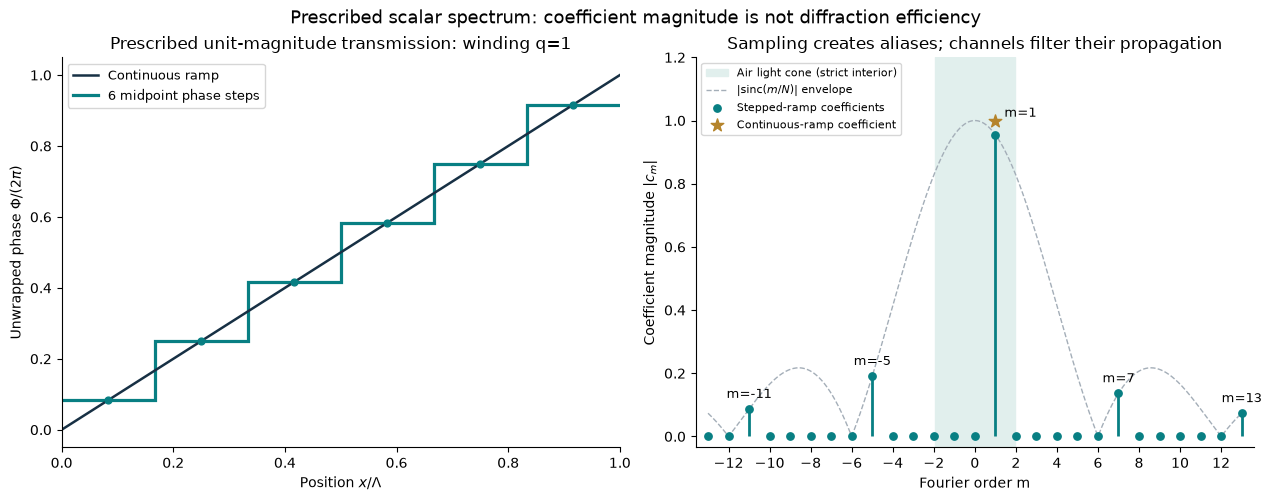

Maximum complex coefficient error against independent quadrature: 3.381e-08
Truncated scalar Parseval sum: 0.99998480 (not a Maxwell power balance)


In [10]:
PHASE_STEPS, PHASE_WINDING = 6, 1
SPECTRAL_PERIOD_UM, SPECTRAL_WAVELENGTH_UM, SPECTRAL_OUTPUT_INDEX = 3.0, 1.55, 1.0
assert isinstance(PHASE_STEPS, int) and PHASE_STEPS >= 2
assert isinstance(PHASE_WINDING, int)
spectral_m = np.arange(-2*PHASE_STEPS-1, 2*PHASE_STEPS+2)

def sampled_phase_coefficients(orders, steps, winding):
    orders = np.asarray(orders, dtype=int)
    centers = (np.arange(steps)+.5)/steps
    return np.sinc(orders/steps)*np.mean(np.exp(2j*np.pi*(winding-orders[:, None])*centers), axis=1)

coefficients = sampled_phase_coefficients(spectral_m, PHASE_STEPS, PHASE_WINDING)
allowed_alias = (spectral_m-PHASE_WINDING) % PHASE_STEPS == 0
expected = np.zeros_like(coefficients)
ell = (spectral_m[allowed_alias]-PHASE_WINDING)//PHASE_STEPS
expected[allowed_alias] = (-1.)**ell*np.sinc(spectral_m[allowed_alias]/PHASE_STEPS)
assert np.allclose(coefficients, expected, atol=1e-14)
# Independent quadrature: evaluate actual t(x), not the integrated formula.
quadrature_points = PHASE_STEPS*4096
u_quad = (np.arange(quadrature_points)+.5)/quadrature_points
t_quad = np.exp(2j*np.pi*PHASE_WINDING*(np.floor(u_quad*PHASE_STEPS)+.5)/PHASE_STEPS)
quadrature = np.array([np.mean(t_quad*np.exp(-2j*np.pi*m*u_quad)) for m in spectral_m])
quadrature_error = float(np.max(np.abs(coefficients-quadrature)))
assert quadrature_error < 1e-7
# Parseval is a scalar Fourier identity, not electromagnetic energy conservation.
wide_orders = np.arange(-20000, 20001)
parseval_sum = np.sum(np.abs(sampled_phase_coefficients(wide_orders, PHASE_STEPS, PHASE_WINDING))**2)
assert abs(parseval_sum-1) < 1e-4
if PHASE_STEPS == 6 and PHASE_WINDING == 1:
    assert np.isclose(abs(coefficients[spectral_m == 1][0])**2, .91189065278104)

fig, axes = plt.subplots(1, 2, figsize=(12.6, 4.9), constrained_layout=True)
edges = np.linspace(0, 1, PHASE_STEPS+1)
centers = (np.arange(PHASE_STEPS)+.5)/PHASE_STEPS
phase_mid = PHASE_WINDING*centers
axes[0].plot([0, 1], [0, PHASE_WINDING], color='#173044', lw=1.8, label='Continuous ramp')
axes[0].stairs(phase_mid, edges, baseline=None, color='#087f83', lw=2.3, label=f'{PHASE_STEPS} midpoint phase steps')
axes[0].scatter(centers, phase_mid, s=24, color='#087f83', zorder=3)
axes[0].set(xlabel=r'Position $x/\Lambda$', ylabel=r'Unwrapped phase $\Phi/(2\pi)$', xlim=(0, 1),
            title=f'Prescribed unit-magnitude transmission: winding q={PHASE_WINDING}')
axes[0].legend(fontsize=9)
open_limit = SPECTRAL_OUTPUT_INDEX*SPECTRAL_PERIOD_UM/SPECTRAL_WAVELENGTH_UM
axes[1].axvspan(-open_limit, open_limit, color='#e1efed', label='Air light cone (strict interior)')
envelope_m = np.linspace(spectral_m.min(), spectral_m.max(), 801)
axes[1].plot(envelope_m, np.abs(np.sinc(envelope_m/PHASE_STEPS)), '--', color='#a4aeb8', lw=1, label=r'$|\mathrm{sinc}(m/N)|$ envelope')
axes[1].vlines(spectral_m, 0, np.abs(coefficients), color='#087f83', lw=2)
axes[1].scatter(spectral_m, np.abs(coefficients), color='#087f83', s=28, zorder=3, label='Stepped-ramp coefficients')
axes[1].scatter([PHASE_WINDING], [1], marker='*', s=90, color='#b5842b', zorder=4, label='Continuous-ramp coefficient')
for m, c in zip(spectral_m, coefficients):
    if abs(c) > .05:
        axes[1].annotate(f'm={m}', (m, abs(c)), xytext=(18, 13) if m == PHASE_WINDING else (0, 8), textcoords='offset points', ha='center', fontsize=9)
axes[1].set(xlabel='Fourier order m', ylabel=r'Coefficient magnitude $|c_m|$', ylim=(-.035, 1.2),
            xlim=(spectral_m.min()-.6, spectral_m.max()+.6), title='Sampling creates aliases; channels filter their propagation')
axes[1].set_xticks(np.arange(-2*PHASE_STEPS, 2*PHASE_STEPS+1, 2))
axes[1].legend(fontsize=8, loc='upper left')
fig.suptitle('Prescribed scalar spectrum: coefficient magnitude is not diffraction efficiency', fontsize=13)
plt.show()
print(f'Maximum complex coefficient error against independent quadrature: {quadrature_error:.3e}')
print(f'Truncated scalar Parseval sum: {parseval_sum:.8f} (not a Maxwell power balance)')


## 10. Extend the channel test to a rectangular lattice

For periods $\Lambda_x,\Lambda_y$ and incident azimuth $\varphi_i$,

$$q_{x,m}=n_i\sin\theta_i\cos\varphi_i+m\lambda_0/\Lambda_x,$$
$$q_{y,n}=n_i\sin\theta_i\sin\varphi_i+n\lambda_0/\Lambda_y.$$

Classify $\sqrt{q_{x,m}^2+q_{y,n}^2}$ against $n_o$, not $|q_x|$ alone. A circular light cone replaces the one-dimensional interval. This small example enumerates all potentially open pairs inside conservative bounds. It does not simulate a two-dimensional grating.


In [11]:
def rectangular_orders(px, py, wavelength, theta, phi, ni, no):
    validate_inputs(px, wavelength, theta, ni, no)
    validate_inputs(py, wavelength, theta, ni, no)
    if not np.isfinite(phi):
        raise ValueError("Azimuth must be finite")
    q = ni*np.sin(np.deg2rad(theta))
    qx0, qy0 = q*np.cos(np.deg2rad(phi)), q*np.sin(np.deg2rad(phi))
    lo_x, hi_x = int(np.floor((-no-qx0)*px/wavelength))-1, int(np.ceil((no-qx0)*px/wavelength))+1
    lo_y, hi_y = int(np.floor((-no-qy0)*py/wavelength))-1, int(np.ceil((no-qy0)*py/wavelength))+1
    if (hi_x-lo_x+1)*(hi_y-lo_y+1) > MAX_ENUMERATED_ORDERS:
        raise ValueError("Too many 2D orders for this teaching example")
    result = []
    for m in range(lo_x, hi_x+1):
        for n in range(lo_y, hi_y+1):
            qx, qy = qx0+m*wavelength/px, qy0+n*wavelength/py
            radius = np.hypot(qx, qy)
            state = str(classify_q(radius, no))
            result.append((m, n, qx, qy, state))
    return result

pairs = rectangular_orders(.8, 1.2, 1.55, 45, 0, 1, 1.5)
open_pairs = {(m, n) for m, n, _, _, state in pairs if state == "open"}
assert open_pairs == {(-1, 0), (0, -1), (0, 0), (0, 1)}
assert {(m, n) for m, n, _, _, s in rectangular_orders(.8, 1.2, 1.55, 45, 0, 1, 1) if s == "open"} == {(0, 0)}
print("Open rectangular-lattice orders in index 1.5:", sorted(open_pairs))
show_table(["m", "n", "kx/k0", "ky/k0", "State"],
           [(m, n, f"{qx:.6f}", f"{qy:.6f}", state) for m, n, qx, qy, state in pairs if state != "closed"])


Open rectangular-lattice orders in index 1.5: [(-1, 0), (0, -1), (0, 0), (0, 1)]


m,n,kx/k0,ky/k0,State
-1,0,-1.230393,0.000000,open
0,-1,0.707107,-1.291667,open
0,0,0.707107,0.000000,open
0,1,0.707107,1.291667,open


## 11. Optional Jupyter sliders

The saved reference output below is a short status message. Set `ENABLE_WIDGETS=True` in the first cell, restart, and run the notebook in Jupyter to enable controls. The sliders reuse the same `floquet_orders` function. The public lab's standalone HTML explorer provides immediate browser interaction without a Python kernel.


In [12]:
if ENABLE_WIDGETS:
    import ipywidgets as widgets

    def explore(period_um, wavelength_um, theta_deg, n_in, n_out):
        result = floquet_orders(period_um, wavelength_um, theta_deg, n_in, n_out)
        print_channels(result, "Selected output region")

    controls = widgets.interactive(
        explore,
        period_um=widgets.FloatSlider(value=PERIOD_UM, min=.4, max=5, step=.01, description="Period (um)", continuous_update=False),
        wavelength_um=widgets.FloatSlider(value=WAVELENGTH_UM, min=.4, max=4, step=.01, description="Lambda (um)", continuous_update=False),
        theta_deg=widgets.FloatSlider(value=THETA_DEG, min=-75, max=75, step=.5, description="Angle (deg)", continuous_update=False),
        n_in=widgets.FloatSlider(value=N_IN, min=1, max=2.5, step=.05, description="n incident", continuous_update=False),
        n_out=widgets.FloatSlider(value=N_OUT, min=1, max=2.5, step=.05, description="n output", continuous_update=False))
    display(controls)
else:
    print("Reference execution complete. Set ENABLE_WIDGETS=True in Jupyter for sliders, or use the browser explorer in the lab.")


Reference execution complete. Set ENABLE_WIDGETS=True in Jupyter for sliders, or use the browser explorer in the lab.


## 12. Interpret the evidence

Report the open sets and signed angles for the optical and microwave cases; explain the cutoff tests, Fresnel normalization, and finite-array model limits. Include one proposed full-wave comparison using the lab's interface or ridge-grating outline.

For extensions, vary the period or output index, implement a material-dispersion curve, or compare the scalar factors with a documented element pattern. Keep analytical, prescribed-model, full-wave, and measured results clearly identified. A successful channel calculation does not establish that a designed metasurface excites the desired channel efficiently.
